In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
from pathlib import Path

file_path = Path("Group A Deadline-11 Nov 26 Model_C11 - Copy of May.csv")

if not file_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        file_path = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError(
            "Place the C11 CSV in the notebook folder or update file_path."
        )

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (193, 10)


,S.No,Country,City,Company,CONTACT,Google Map,Category,Clean_Category,Rating,Review
0,1,India,Mumbai,Rita's Glaam Salon,7039157910,https://maps.app.goo.gl/jhFBjK6GB8CBtbu3A?g_st=ic,Salon,Salon,4.8,43
1,2,India,Mumbai,Fabulous Glow Salon,8169690114,https://maps.app.goo.gl/tEdVWYn18SABKjCh6?g_st=ic,Salon,Salon,4.6,23
2,3,India,Mumbai,Relax Beauty Parlour,9867415626,https://maps.app.goo.gl/WNRrbEX6iQ5vjV3p6?g_st=ic,Salon,Salon,3.5,25
3,4,India,Mumbai,Sassanian Restaurent and Bakery,8976091334,https://maps.app.goo.gl/7XYrYtRdAsaCqpnPA?g_st=ic,Bakery,Restaurant,3.9,2905
4,5,India,Mumbai,Balwas Restaurent,2222070717,https://maps.app.goo.gl/ZT2iE8XwdLtrAn9s8?g_st=ic,Restaurent,Restaurant,4.2,3396



Columns:
['S.No', 'Country', 'City', 'Company', 'CONTACT', 'Google Map', 'Category', 'Clean_Category', 'Rating', 'Review']


In [3]:
required_columns = ["Country", "Company", "Rating", "Review"]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Required columns missing from dataset: {missing_columns}")

# Standardise text fields without changing the original business categories.
df["Country"] = df["Country"].astype("string").str.strip()
df["Company"] = df["Company"].astype("string").str.strip()

# Convert Rating and Review to numeric values.
# Handles values such as '1,250' in the Review column.
df["Rating"] = pd.to_numeric(
    df["Rating"].astype("string").str.replace(",", "", regex=False).str.strip(),
    errors="coerce"
)
df["Review"] = pd.to_numeric(
    df["Review"].astype("string").str.replace(",", "", regex=False).str.strip(),
    errors="coerce"
)

# Treat negative values and impossible ratings as missing.
df.loc[df["Rating"].notna() & ~df["Rating"].between(0, 5), "Rating"] = np.nan
df.loc[df["Review"] < 0, "Review"] = np.nan

print("Missing Rating values:", df["Rating"].isna().sum())
print("Missing Review values:", df["Review"].isna().sum())
display(df[["Company", "Country", "Rating", "Review"]].head())

Missing Rating values: 0
Missing Review values: 0


,Company,Country,Rating,Review
0,Rita's Glaam Salon,India,4.8,43
1,Fabulous Glow Salon,India,4.6,23
2,Relax Beauty Parlour,India,3.5,25
3,Sassanian Restaurent and Bakery,India,3.9,2905
4,Balwas Restaurent,India,4.2,3396


In [4]:
df["Business_Type"] = np.where(
    df["Country"].str.casefold().eq("india"),
    "Indian",
    "Foreign"
)

# Missing country values should not automatically be labelled Foreign.
df.loc[df["Country"].isna() | df["Country"].eq(""), "Business_Type"] = "Country Not Available"

print("Business origin counts:")
display(df["Business_Type"].value_counts(dropna=False).to_frame("Business_Count"))

# Optional country-level summary
display(
    df.groupby("Business_Type", dropna=False)
      .size()
      .reset_index(name="Business_Count")
)

Business origin counts:


,Business_Count
Business_Type,
Indian,157
Foreign,36


,Business_Type,Business_Count
0,Foreign,36
1,Indian,157


In [5]:
# A business is considered to have review data only when BOTH
# rating and review count are present and greater than zero.
df["Review_Data_Available"] = np.where(
    df["Rating"].notna()
    & df["Review"].notna()
    & (df["Rating"] > 0)
    & (df["Review"] > 0),
    "Review Data Available",
    "No Review Data"
)

print("Review data availability:")
display(df["Review_Data_Available"].value_counts().to_frame("Business_Count"))

Review data availability:


,Business_Count
Review_Data_Available,
Review Data Available,191
No Review Data,2


In [6]:
df["Rating_Score"] = df["Rating"] / 5
df["Log_Reviews"] = np.log1p(df["Review"])

valid_review_mask = df["Review_Data_Available"].eq("Review Data Available")

# Calculate min-max scaling only from businesses with valid review data.
if valid_review_mask.any():
    min_log = df.loc[valid_review_mask, "Log_Reviews"].min()
    max_log = df.loc[valid_review_mask, "Log_Reviews"].max()

    if max_log == min_log:
        df["Review_Volume_Score"] = np.where(valid_review_mask, 0.0, np.nan)
    else:
        df["Review_Volume_Score"] = np.nan
        df.loc[valid_review_mask, "Review_Volume_Score"] = (
            (df.loc[valid_review_mask, "Log_Reviews"] - min_log)
            / (max_log - min_log)
        )

    df["Review_Score"] = (
        0.60 * df["Rating_Score"]
        + 0.40 * df["Review_Volume_Score"]
    )
else:
    df["Review_Volume_Score"] = np.nan
    df["Review_Score"] = np.nan

display(
    df[[
        "Company", "Rating", "Review", "Rating_Score",
        "Log_Reviews", "Review_Volume_Score", "Review_Score"
    ]].head(10)
)

,Company,Rating,Review,Rating_Score,Log_Reviews,Review_Volume_Score,Review_Score
0,Rita's Glaam Salon,4.8,43,0.96,3.78419,0.321930,0.704772
1,Fabulous Glow Salon,4.6,23,0.92,3.178054,0.258801,0.65552
2,Relax Beauty Parlour,3.5,25,0.7,3.258097,0.267138,0.526855
3,Sassanian Restaurent and Bakery,3.9,2905,0.78,7.974533,0.758351,0.77134
4,Balwas Restaurent,4.2,3396,0.84,8.130648,0.774610,0.813844
5,Kyani and Co.,4.1,13835,0.82,9.535029,0.920875,0.86035
6,Bhakti SuperMart,4.4,103,0.88,4.644391,0.411519,0.692608
7,RidhiSidhi SuperMarket,4.6,45,0.92,3.828641,0.326559,0.682624
8,Shri Krishna Dairy Farm,4.2,12,0.84,2.564949,0.194947,0.581979
9,Sumit Dairy,4.5,23,0.9,3.178054,0.258801,0.64352


In [7]:
df["Review_Class"] = "No Review Data"

if valid_review_mask.sum() > 0:
    q1 = df.loc[valid_review_mask, "Review_Score"].quantile(0.25)
    q3 = df.loc[valid_review_mask, "Review_Score"].quantile(0.75)

    df.loc[valid_review_mask & (df["Review_Score"] <= q1), "Review_Class"] = "Low"
    df.loc[
        valid_review_mask
        & (df["Review_Score"] > q1)
        & (df["Review_Score"] <= q3),
        "Review_Class"
    ] = "Medium"
    df.loc[valid_review_mask & (df["Review_Score"] > q3), "Review_Class"] = "High"

    print(f"Low threshold (Q1): {q1:.6f}")
    print(f"High threshold (Q3): {q3:.6f}")
else:
    print("No valid review records found; review classes cannot be calculated.")

print("\nReview class counts:")
display(df["Review_Class"].value_counts().to_frame("Business_Count"))

print("\nReview class percentages:")
display(
    (df["Review_Class"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

Low threshold (Q1): 0.661803
High threshold (Q3): 0.774418

Review class counts:


,Business_Count
Review_Class,
Medium,95
Low,48
High,48
No Review Data,2



Review class percentages:


,Percentage
Review_Class,
Medium,49.22
Low,24.87
High,24.87
No Review Data,1.04


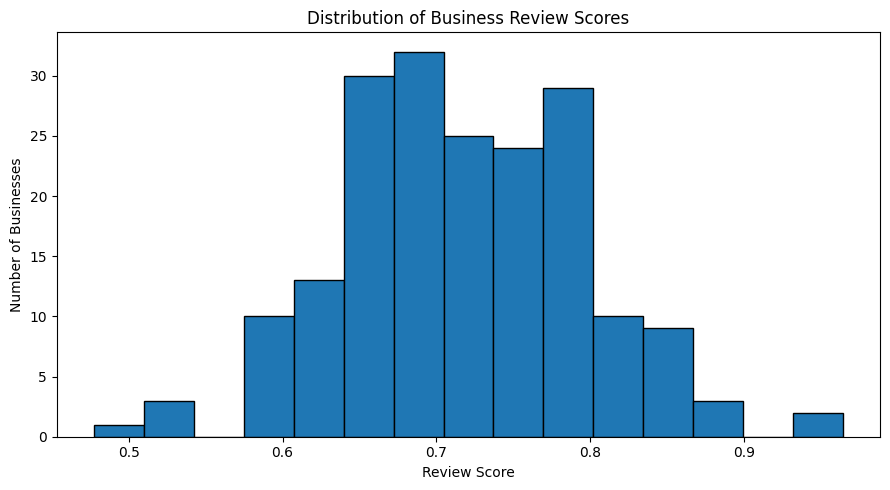

In [8]:
plt.figure(figsize=(9, 5))
plt.hist(df.loc[valid_review_mask, "Review_Score"].dropna(), bins=15, edgecolor="black")
plt.xlabel("Review Score")
plt.ylabel("Number of Businesses")
plt.title("Distribution of Business Review Scores")
plt.tight_layout()
plt.show()

In [9]:
priority_order = ["High", "Medium", "Low", "No Review Data"]
df["Review_Class"] = pd.Categorical(
    df["Review_Class"],
    categories=priority_order,
    ordered=True
)

display_columns = [
    col for col in [
        "S.No", "Company", "Country", "Business_Type", "City",
        "Category", "Clean_Category", "Rating", "Review",
        "Rating_Score", "Review_Volume_Score", "Review_Score",
        "Review_Class", "Google Map", "CONTACT"
    ] if col in df.columns
]

high_priority = df[df["Review_Class"] == "High"][display_columns].sort_values(
    "Review_Score", ascending=False
)
medium_priority = df[df["Review_Class"] == "Medium"][display_columns].sort_values(
    "Review_Score", ascending=False
)
low_priority = df[df["Review_Class"] == "Low"][display_columns].sort_values(
    "Review_Score", ascending=True
)
no_review_data = df[df["Review_Class"] == "No Review Data"][display_columns]

print("HIGH PRIORITY")
display(high_priority)

print("MEDIUM PRIORITY")
display(medium_priority)

print("LOW PRIORITY")
display(low_priority)

print("NO REVIEW DATA")
display(no_review_data)

HIGH PRIORITY


,S.No,Company,Country,Business_Type,City,Category,Clean_Category,Rating,Review,Rating_Score,Review_Volume_Score,Review_Score,Review_Class,Google Map,CONTACT
94,96,38 Barracks Restaurant and Bar- Connaught Place,India,Indian,Delhi,Restaurent,Restaurant,4.7,29576,0.94,1.000000,0.964,High,https://maps.app.goo.gl/XqfeXZxicH3s9RC49?g_st=ic,8800661263
82,84,Milan A Speciality Restaurant,India,Indian,Lucknow,Fitness,Restaurant,4.8,16302,0.96,0.937964,0.951185,High,https://maps.app.goo.gl/mFgk173FutVnJPiz6?g_st=ic,9936888000
84,86,Baati Chokha Restaurant,India,Indian,Lucknow,Fitness,Restaurant,4.4,9864,0.88,0.885644,0.882257,High,https://maps.app.goo.gl/ZFxQE5ewc4wVKhQ96?g_st=ic,5224005642
86,88,Moti Mahal Delux,India,Indian,Lucknow,Restaurent,Restaurant,4.2,16321,0.84,0.938085,0.879234,High,https://maps.app.goo.gl/Gz3mJJ8K1uETReEE7?g_st...,5224048101
172,174,Megma Restaurant & Banquets,India,Indian,Gujarat,Restaurant,Restaurant,4.6,4344,0.92,0.800245,0.872098,High,https://maps.app.goo.gl/PhVTob92AjwdniE98,9512340283
150,152,Jay Khodiyar Hotel,India,Indian,Gujarat,Restaurant,Restaurant,4.3,8971,0.86,0.875762,0.866305,High,https://maps.app.goo.gl/14M6BehpXf9Wt7i9A,9723810112
68,70,Baba Falooda & Chat Corner,India,Indian,Delhi,Restaurent,Restaurant,4.4,6328,0.88,0.839417,0.863767,High,https://www.google.com/maps/search/?api=1&quer...,+91 72728 10404
174,176,Dakshin Bhojnam,India,Indian,Gujarat,Restaurant,Restaurant,4.8,1961,0.96,0.717440,0.862976,High,https://maps.app.goo.gl/hW4oiREpz1mj1UND7,8868820320
5,6,Kyani and Co.,India,Indian,Mumbai,Restaurent,Restaurant,4.1,13835,0.82,0.920875,0.86035,High,https://maps.app.goo.gl/BFXQADocGgA4Rw8z9?g_st=ic,8928616793
95,97,Tamra Restaurant,India,Indian,Delhi,Restaurent,Restaurant,4.4,5254,0.88,0.820049,0.85602,High,https://maps.app.goo.gl/g5WyNttU61j1rKBt7?g_st=ic,9599787836


MEDIUM PRIORITY


,S.No,Company,Country,Business_Type,City,Category,Clean_Category,Rating,Review,Rating_Score,Review_Volume_Score,Review_Score,Review_Class,Google Map,CONTACT
191,193,SHIVGIRI RESORT,India,Indian,Gujarat,Restaurant,Restaurant,4.4,737,0.88,0.615605,0.774242,Medium,https://www.google.com/maps/search/?api=1&quer...,+91 91570 99066
125,127,Nityanand Restaurant - Pure Veg,India,Indian,Mumbai,Restaurant,Restaurant,3.8,3992,0.76,0.791446,0.772578,Medium,https://www.google.com/maps/search/?api=1&quer...,+91 91375 15048
3,4,Sassanian Restaurent and Bakery,India,Indian,Mumbai,Bakery,Restaurant,3.9,2905,0.78,0.758351,0.77134,Medium,https://maps.app.goo.gl/7XYrYtRdAsaCqpnPA?g_st=ic,8976091334
33,35,Swagat Veg Treat,India,Indian,Delhi,Restaurent,Restaurant,4.7,288,0.94,0.517963,0.771185,Medium,https://www.google.com/maps/search/?api=1&quer...,+91 22 2414 2470
53,55,Anil Wine N Dine,India,Indian,Delhi,Restaurent,Restaurant,4.1,1564,0.82,0.693894,0.769558,Medium,https://www.google.com/maps/search/?api=1&quer...,+91 98679 52228
149,151,Hotel Saurashtra,India,Indian,Gujarat,Restaurant,Restaurant,4.1,1386,0.82,0.681319,0.764527,Medium,https://maps.app.goo.gl/pzX5c7rJBQjKRDQU6,7621017519
187,189,Simply South Refreshment,India,Indian,Gujarat,Restaurant,Restaurant,4.0,1813,0.8,0.709271,0.763708,Medium,https://www.google.com/maps/search/?api=1&quer...,+91 82388 02994
119,121,Kokan Sagar Resturant,India,Indian,Mumbai,Restaurant,Restaurant,4.0,1733,0.8,0.704574,0.76183,Medium,https://www.google.com/maps/search/?api=1&quer...,+91 91371 13592
12,14,HL Vadapav,India,Indian,Gujarat,Food shop,Restaurant,4.1,1297,0.82,0.674411,0.761765,Medium,https://maps.app.goo.gl/UdTqzdeB3ix9rARd7?g_st=ic,9427050449
148,150,Sangeeta Restaurant,India,Indian,Gujarat,Restaurant,Restaurant,4.4,489,0.88,0.572952,0.757181,Medium,https://maps.app.goo.gl/BQsbqKjG9Lzg1Ac99,9727192029


LOW PRIORITY


,S.No,Company,Country,Business_Type,City,Category,Clean_Category,Rating,Review,Rating_Score,Review_Volume_Score,Review_Score,Review_Class,Google Map,CONTACT
165,167,hotel tavakkal & restaurant,India,Indian,Mumbai,Restaurant,Restaurant,2.8,59,0.56,0.354232,0.477693,Low,https://www.google.com/maps/search/?api=1&quer...,+91 80970 28057
157,159,MALABAR RESTAURANT,India,Indian,Mumbai,Restaurant,Restaurant,4.0,4,0.8,0.095431,0.518172,Low,https://www.google.com/maps/search/?api=1&quer...,+91 75609 94677
2,3,Relax Beauty Parlour,India,Indian,Mumbai,Salon,Salon,3.5,25,0.7,0.267138,0.526855,Low,https://maps.app.goo.gl/WNRrbEX6iQ5vjV3p6?g_st=ic,9867415626
163,165,NATIONAL HINDU RESTAURANT,India,Indian,Mumbai,Restaurant,Restaurant,3.7,15,0.74,0.216572,0.530629,Low,https://www.google.com/maps/search/?api=1&quer...,+91 98330 76692
47,49,Delicacy Restaurant,India,Indian,Delhi,Restaurent,Restaurant,4.0,21,0.8,0.249739,0.579896,Low,https://www.google.com/maps/search/?api=1&quer...,+91 86300 57407
8,10,Shri Krishna Dairy Farm,India,Indian,Mumbai,Dairy Shop,Dairy Shop,4.2,12,0.84,0.194947,0.581979,Low,https://maps.app.goo.gl/YxUV2SxGBXMewKxg8?g_st=ic,2222072065
32,34,Cafe Farmer Stores & Restaurant,India,Indian,Delhi,Restaurent,Restaurant,3.6,82,0.72,0.388028,0.587211,Low,https://www.google.com/maps/search/?api=1&quer...,+91 98922 20119
118,120,Mughal Flavour Grand,India,Indian,Mumbai,Restaurant,Restaurant,3.3,198,0.66,0.479103,0.587641,Low,https://www.google.com/maps/search/?api=1&quer...,+91 78668 73786
162,164,Hotel Nityanand,India,Indian,Mumbai,Restaurant,Restaurant,4.0,28,0.8,0.278511,0.591404,Low,https://www.google.com/maps/search/?api=1&quer...,+91 83694 57648
79,81,Bajaj world,India,Indian,Lucknow,Services,Electrical,4.5,6,0.9,0.130474,0.59219,Low,https://maps.app.goo.gl/T84ZdA4k3VFo1CyM9?g_st=ic,9129777370


NO REVIEW DATA


,S.No,Company,Country,Business_Type,City,Category,Clean_Category,Rating,Review,Rating_Score,Review_Volume_Score,Review_Score,Review_Class,Google Map,CONTACT
137,139,Iheanacho Obidike,USA,Foreign,Las Vegas,Pharmacy,Pharmacy,0.0,0,0.0,NaN,<NA>,No Review Data,https://maps.app.goo.gl/jm7GTtK3PS3jc6kM9,17024866000
146,148,Vadu Tanu Restaurant,India,Indian,Gujarat,Restaurant,Restaurant,0.0,0,0.0,NaN,<NA>,No Review Data,https://maps.app.goo.gl/vcNpVdwCei4368de7,9426523145


In [10]:
origin_review_table = pd.crosstab(
    df["Business_Type"],
    df["Review_Class"],
    dropna=False
)
display(origin_review_table)

origin_review_percentage = (
    pd.crosstab(
        df["Business_Type"],
        df["Review_Class"],
        normalize="index",
        dropna=False
    ) * 100
).round(2)

print("Percentage distribution within each origin:")
display(origin_review_percentage)

Review_Class,High,Medium,Low,No Review Data
Business_Type,,,,
Foreign,7,27,1,1
Indian,41,68,47,1


Percentage distribution within each origin:


Review_Class,High,Medium,Low,No Review Data
Business_Type,,,,
Foreign,19.44,75.00,2.78,2.78
Indian,26.11,43.31,29.94,0.64


In [11]:
review_summary = (
    df[df["Review_Class"] != "No Review Data"]
    .groupby("Review_Class", observed=False)
    .agg(
        Business_Count=("Company", "count"),
        Average_Rating=("Rating", "mean"),
        Average_Reviews=("Review", "mean"),
        Average_Review_Score=("Review_Score", "mean"),
        Median_Reviews=("Review", "median")
    )
    .reindex(["High", "Medium", "Low"])
    .round(2)
)

display(review_summary)

,Business_Count,Average_Rating,Average_Reviews,Average_Review_Score,Median_Reviews
Review_Class,,,,,
High,48,4.41,3735.02,0.82,1986.0
Medium,95,4.31,481.21,0.72,277.0
Low,48,4.19,62.1,0.62,29.5


In [12]:
model_df = df.loc[valid_review_mask, ["Rating", "Review", "Review_Class"]].dropna().copy()

X = model_df[["Rating", "Review"]]
y = model_df["Review_Class"].astype(str)

class_counts = y.value_counts()
print("Records available for model:", len(model_df))
display(class_counts.to_frame("Count"))

if y.nunique() < 2:
    raise ValueError("At least two review classes are needed to train the classifier.")

# Use a stratified split only when every class has at least 2 records.
if class_counts.min() < 2:
    raise ValueError(
        "At least one class has fewer than 2 records. "
        "A stratified train/test split is not reliable for this dataset."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Records available for model: 191


,Count
Review_Class,
Medium,95
Low,48
High,48


Test Accuracy: 0.8974

Classification Report:
              precision    recall  f1-score   support

        High       0.90      0.90      0.90        10
         Low       0.90      0.90      0.90        10
      Medium       0.89      0.89      0.89        19

    accuracy                           0.90        39
   macro avg       0.90      0.90      0.90        39
weighted avg       0.90      0.90      0.90        39



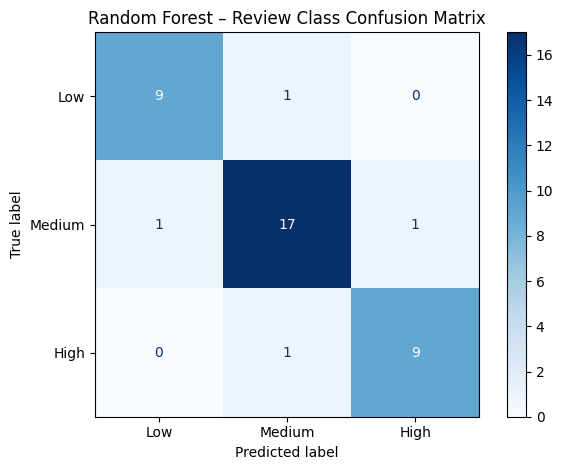

In [13]:
labels = ["Low", "Medium", "High"]

cm = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest – Review Class Confusion Matrix")
plt.tight_layout()
plt.show()

,Feature,Importance
1,Review,0.752187
0,Rating,0.247813


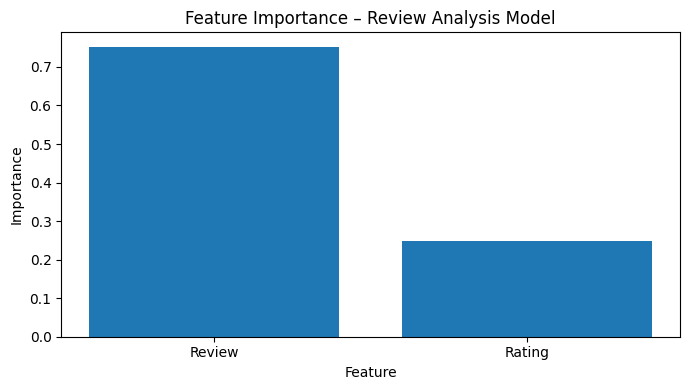

In [14]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(7, 4))
plt.bar(feature_importance["Feature"], feature_importance["Importance"])
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Feature Importance – Review Analysis Model")
plt.tight_layout()
plt.show()

In [15]:
# Five-fold cross-validation is possible only if every class has at least 5 records.
if class_counts.min() >= 5:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")

    print("Cross-validation scores:", np.round(cv_scores, 4))
    print("Mean cross-validation accuracy:", round(cv_scores.mean(), 4))
else:
    print("Skipped 5-fold cross-validation because at least one class has fewer than 5 records.")

Cross-validation scores: [0.9231 0.9211 0.8421 0.9474 0.9737]
Mean cross-validation accuracy: 0.9215


In [16]:
# Predict for every business with valid Rating and Review data.
df["Predicted_Review_Class"] = "No Review Data"
df["Predicted_Review_Probability"] = np.nan

prediction_mask = valid_review_mask & df["Rating"].notna() & df["Review"].notna()

df.loc[prediction_mask, "Predicted_Review_Class"] = model.predict(
    df.loc[prediction_mask, ["Rating", "Review"]]
)

all_probabilities = model.predict_proba(
    df.loc[prediction_mask, ["Rating", "Review"]]
)

df.loc[prediction_mask, "Predicted_Review_Probability"] = (
    all_probabilities.max(axis=1)
)

display(
    df[[
        "Company", "Country", "Business_Type", "Rating", "Review",
        "Review_Score", "Review_Class",
        "Predicted_Review_Class", "Predicted_Review_Probability"
    ]].head(20)
)

,Company,Country,Business_Type,Rating,Review,Review_Score,Review_Class,Predicted_Review_Class,Predicted_Review_Probability
0,Rita's Glaam Salon,India,Indian,4.8,43,0.704772,Medium,Medium,0.985
1,Fabulous Glow Salon,India,Indian,4.6,23,0.65552,Low,Low,0.925
2,Relax Beauty Parlour,India,Indian,3.5,25,0.526855,Low,Low,0.990
3,Sassanian Restaurent and Bakery,India,Indian,3.9,2905,0.77134,Medium,Medium,0.845
4,Balwas Restaurent,India,Indian,4.2,3396,0.813844,High,High,0.975
5,Kyani and Co.,India,Indian,4.1,13835,0.86035,High,High,1.000
6,Bhakti SuperMart,India,Indian,4.4,103,0.692608,Medium,Medium,0.980
7,RidhiSidhi SuperMarket,India,Indian,4.6,45,0.682624,Medium,Medium,0.965
8,Shri Krishna Dairy Farm,India,Indian,4.2,12,0.581979,Low,Low,0.965
9,Sumit Dairy,India,Indian,4.5,23,0.64352,Low,Low,0.995


In [17]:
comparison = pd.crosstab(
    df["Review_Class"].astype(str),
    df["Predicted_Review_Class"].astype(str),
    dropna=False
)
display(comparison)

Predicted_Review_Class,High,Low,Medium,No Review Data
Review_Class,,,,
High,47,0,1,0
Low,0,47,1,0
Medium,1,1,93,0
No Review Data,0,0,0,2


In [18]:
import os
import pandas as pd

# Create output folder
output_folder = "C11_CSV_Outputs"
os.makedirs(output_folder, exist_ok=True)

# Ensure classification columns are strings
df["Business_Type"] = df["Business_Type"].astype("string").str.strip()
df["Review_Class"] = df["Review_Class"].astype("string").str.strip()

# Sort every business-level dataset by ascending serial number.
# A temporary numeric key ensures 2 comes before 10 (not 10 before 2).
serial_column = "S.No"
if serial_column not in df.columns:
    raise KeyError(
        f"'{serial_column}' column was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

def sort_by_serial(data):
    data = data.copy()
    data["_serial_sort_key"] = pd.to_numeric(
        data[serial_column].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )
    data = data.sort_values(
        by=["_serial_sort_key", serial_column],
        ascending=[True, True],
        na_position="last",
        kind="stable"
    )
    return data.drop(columns="_serial_sort_key").reset_index(drop=True)

# 1. Complete dataset
sorted_df = sort_by_serial(df)
sorted_df.to_csv(
    f"{output_folder}/C11_Final_Review_Analysis_Output.csv",
    index=False
)

# 2. Separate Indian and Foreign businesses
indian_businesses = sort_by_serial(
    df[df["Business_Type"].str.casefold() == "indian"]
)
foreign_businesses = sort_by_serial(
    df[df["Business_Type"].str.casefold() == "foreign"]
)

indian_businesses.to_csv(
    f"{output_folder}/C11_Indian_Businesses.csv",
    index=False
)
foreign_businesses.to_csv(
    f"{output_folder}/C11_Foreign_Businesses.csv",
    index=False
)

# 3. Separate review priority files
for priority in ["High", "Medium", "Low", "No Review Data"]:
    priority_df = sort_by_serial(
        df[df["Review_Class"].str.casefold() == priority.casefold()]
    )
    filename = priority.replace(" ", "_")
    priority_df.to_csv(
        f"{output_folder}/C11_{filename}_Priority.csv",
        index=False
    )

# 4. Indian vs Foreign review summary (summary table; no serial number)
indian_foreign_summary = pd.crosstab(
    df["Business_Type"],
    df["Review_Class"]
)
indian_foreign_summary.to_csv(
    f"{output_folder}/C11_Indian_Foreign_Review_Summary.csv"
)

# 5. Review class summary (summary table; no serial number)
review_class_summary = (
    df["Review_Class"]
    .value_counts(dropna=False)
    .rename_axis("Review_Class")
    .reset_index(name="Business_Count")
)
review_class_summary.to_csv(
    f"{output_folder}/C11_Review_Class_Summary.csv",
    index=False
)

# 6. Feature importance (summary table; no serial number)
if "feature_importance" in globals():
    feature_importance.to_csv(
        f"{output_folder}/C11_Feature_Importance.csv",
        index=False
    )
elif "feature_importance_df" in globals():
    feature_importance_df.to_csv(
        f"{output_folder}/C11_Feature_Importance.csv",
        index=False
    )

# Display generated files
print("All CSV files generated successfully:")
for filename in sorted(os.listdir(output_folder)):
    print(filename)

print("\nIndian businesses:", len(indian_businesses))
print("Foreign businesses:", len(foreign_businesses))
print("\nAll business-level CSV files are sorted by S.No in ascending order.")
print("Output folder:", os.path.abspath(output_folder))


All CSV files generated successfully:
C11_Feature_Importance.csv
C11_Final_Review_Analysis_Output.csv
C11_Foreign_Businesses.csv
C11_High_Priority.csv
C11_Indian_Businesses.csv
C11_Indian_Foreign_Review_Summary.csv
C11_Low_Priority.csv
C11_Medium_Priority.csv
C11_No_Review_Data_Priority.csv
C11_Review_Class_Summary.csv

Indian businesses: 157
Foreign businesses: 36

All business-level CSV files are sorted by S.No in ascending order.
Output folder: C:\Users\arshi\OneDrive\Desktop\BLC-C11\C11_CSV_Outputs


In [19]:
df["Clean_Category"] = (
    df["Clean_Category"]
    .astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

In [20]:
# Category-wise Priority Classification for C11

# Use predicted classes generated by the Random Forest model
priority_column = "Predicted_Review_Class"
category_column = "Clean_Category"

# Create a mapping of categories to their most common predicted priority
category_priority = (
    df[df[priority_column].isin(["High", "Medium", "Low"])]
    .groupby(category_column)[priority_column]
    .agg(lambda x: x.mode().iloc[0])
    .reset_index()
)

# Display categories under each priority
for priority in ["High", "Medium", "Low"]:
    categories = sorted(
        category_priority.loc[
            category_priority[priority_column] == priority,
            category_column
        ].dropna().unique()
    )

    print(f"\n{priority} Priority:")
    print(", ".join(categories) if categories else "No categories found")

# Save category-wise priority output as CSV
category_priority = category_priority.sort_values(
    by=category_column, ascending=True, kind="stable"
).reset_index(drop=True)

category_priority.to_csv(
    "C11_Category_Wise_Priority.csv",
    index=False
)

print("\nCategory-wise priority CSV generated successfully.")


High Priority:
Cafe, Coaching, Grocery Store, Gym, Repair service

Medium Priority:
Cell phone accessory store, Coaching Center, Dessert Shop, Ice Cream Shop, Restaurant, Salon

Low Priority:
Apparel Shop, Ayurvedic Store, Dairy Shop, Electrical, Pharmacy

Category-wise priority CSV generated successfully.


In [21]:
# C11 - Review Score Priority Thresholds

# Exclude businesses with no review data
valid_df = df[
    ~((df["Rating"] == 0) & (df["Review"] == 0))
].copy()

# Calculate percentile thresholds
q1 = valid_df["Review_Score"].quantile(0.25)
q3 = valid_df["Review_Score"].quantile(0.75)

print("C11 REVIEW PRIORITY CLASSIFICATION\n")

print(f"High Priority: Review Score > {q3:.4f}")
print(f"Medium Priority: Review Score > {q1:.4f} and ≤ {q3:.4f}")
print(f"Low Priority: Review Score ≤ {q1:.4f}")
print("No Review Data: Both Rating and Review count are 0")

print("\nPriority Distribution:")

print("\nHigh:", (valid_df["Review_Score"] > q3).sum())
print("Medium:", (
    (valid_df["Review_Score"] > q1) &
    (valid_df["Review_Score"] <= q3)
).sum())
print("Low:", (valid_df["Review_Score"] <= q1).sum())

print(
    "No Review Data:",
    ((df["Rating"] == 0) & (df["Review"] == 0)).sum()
)

C11 REVIEW PRIORITY CLASSIFICATION

High Priority: Review Score > 0.7744
Medium Priority: Review Score > 0.6618 and ≤ 0.7744
Low Priority: Review Score ≤ 0.6618
No Review Data: Both Rating and Review count are 0

Priority Distribution:

High: 48
Medium: 95
Low: 48
No Review Data: 2
